<a href="https://colab.research.google.com/github/Kumarsakthi835/Kumarsakthi835-Insurance-Company-Complaints-Resolutions-Status-and-Recoveries/blob/main/Insurance_Company.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Insurance Company Complaint Pattern & Resolution Analysis using Python(USA 2021–2026)

## Dataset Information
- **Dataset name:** Insurance Company Complaints, Resolutions, Status, and Recoveries Dataset
- **Source repository:** [Kumar S](https://github.com/Kumarsakthi835/Kumarsakthi835-Insurance-Company-Complaints-Resolutions-Status-and-Recoveries)
- **Original source:** [U.S. Government Open Data Portal](https://catalog.data.gov/dataset/insurance-company-complaints-resolutions-status-and-recoveries)
- **Domain:** Finance / Insurance / Consumer Protection
- **Expected size:** 500 rows and 12 columns

## Objective
1. Analyze complaint patterns across different insurance companies
2. Identify the most common complaint reasons and coverage types
3. Monitor complaint resolution status (Open vs Closed)
4. Analyze complaint resolution time (days taken to close)
5. Evaluate recovery amounts by company and coverage type
6. Identify yearly complaint trends from 2021 to 2026
7. Generate descriptive, diagnostic and prescriptive insights

In [ ]:
#Import Libraries
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings('ignore')
print("Libraries imported!")

Libraries imported!


In [ ]:
#Load Dataset from GitHub
url = "https://raw.githubusercontent.com/Kumarsakthi835/Kumarsakthi835-Insurance-Company-Complaints-Resolutions-Status-and-Recoveries/main/Insurance%20Company.csv"
df = pd.read_csv(url)
print("Dataset loaded! Shape:", df.shape)

Dataset loaded! Shape: (500, 12)


In [ ]:
#Initial EDA - Head
df.head()

,Company,File No.,Opened,Closed,Coverage,SubCoverage,Reason,SubReason,Disposition,Conclusion,Recovery,Status
0,Workers' Compensation Trust,7059031,11/11/2023,12/21/2023,Workers' Compensation,NaN,Underwriting,Audit Dispute,Company Position Substantiated,NaN,$0.00,Closed
1,Esurance Insurance Company,7046807,07/26/2022,08/29/2022,Individual Private Passenger,Collision,Claim Handling,Adjuster Handling,Company Position Substantiated,Company Position Upheld,$0.00,Closed
2,"Anthem Health Plans, Inc",7076333,07/03/2025,07/29/2025,A & H,A & H,Underwriting,Premium & Rating,Question of Fact/Contract/Provision/Legal Issue,Contract Provision,$0.00,Closed
3,"ConnectiCare Benefits, Inc.",7047814,09/09/2022,10/06/2022,Individual,Exchange,Claim Handling,Unsatisfactory Settlement/Offer,Company Position Substantiated,Company Position Upheld,$0.00,Closed
4,"Anthem Health Plans, Inc",7068138,09/18/2024,10/09/2024,A & H,Self Funded/ERISA,Claim Handling,Claim Denial,Company Position Substantiated,Provider Issue,$0.00,Closed


In [ ]:
#Initial EDA - Tail
df.tail()

,Company,File No.,Opened,Closed,Coverage,SubCoverage,Reason,SubReason,Disposition,Conclusion,Recovery,Status
495,"Quantum Health, Inc.",7074279,04/16/2025,06/09/2025,A & H,Health Only,Claim Handling,Medical Necessity Denial,NaN,NaN,$0.00,Closed
496,"CaremarkPCS Health, L.L.C. dba CVS Caremark",7088196,08/12/2026,10/01/2026,Group,A & H,Claim Handling,Medical Necessity Denial,Company Position Substantiated,Coverage Denied,$0.00,Closed
497,"Anthem Health Plans, Inc",7072776,02/21/2025,03/11/2025,Individual,A & H,PolicyHolder Service,Coverage Question,Company Position Substantiated,Furnished Information,$0.00,Closed
498,"Anthem Health Plans, Inc",7088040,08/06/2026,09/25/2026,A & H,A & H,Claim Handling,Coordination of Benefits,Question of Fact/Contract/Provision/Legal Issue,Provider Issue,$38.00,Closed
499,"Sentinel Insurance Company, Ltd",7084749,04/16/2026,07/30/2026,Individual Private Passenger,Liability,Claim Handling,Contributory Comparative Negligence,Company Position Substantiated,NaN,$0.00,Closed


In [ ]:
#Initial EDA - Shape & Columns
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (500, 12)
Columns: ['Company', 'File No.', 'Opened', 'Closed', 'Coverage', 'SubCoverage', 'Reason', 'SubReason', 'Disposition', 'Conclusion', 'Recovery', 'Status']


In [ ]:
#Initial EDA - Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Company      500 non-null    object
 1   File No.     500 non-null    int64 
 2   Opened       500 non-null    object
 3   Closed       486 non-null    object
 4   Coverage     475 non-null    object
 5   SubCoverage  410 non-null    object
 6   Reason       480 non-null    object
 7   SubReason    480 non-null    object
 8   Disposition  293 non-null    object
 9   Conclusion   363 non-null    object
 10  Recovery     500 non-null    object
 11  Status       500 non-null    object
dtypes: int64(1), object(11)
memory usage: 47.0+ KB


In [ ]:
#Initial EDA - Statistical Summary
df.describe(include='all')

,Company,File No.,Opened,Closed,Coverage,SubCoverage,Reason,SubReason,Disposition,Conclusion,Recovery,Status
count,500,5.000000e+02,500,486,475,410,480,480,293,363,500,500
unique,136,NaN,397,370,22,39,4,80,11,30,92,6
top,"Anthem Health Plans, Inc",NaN,07/17/2025,09/01/2026,A & H,Health Only,Claim Handling,Claim Denial,Company Position Substantiated,Claim Paid,$0.00,Closed
freq,121,NaN,4,4,147,131,377,48,131,49,403,486
mean,NaN,7.068856e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,1.387182e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,7.006204e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,7.057870e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,7.070980e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,7.080780e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#Initial EDA - Missing Values
print(df.isnull().sum())
print((df.isnull().sum()/len(df)*100).round(2))

Company          0
File No.         0
Opened           0
Closed          14
Coverage        25
SubCoverage     90
Reason          20
SubReason       20
Disposition    207
Conclusion     137
Recovery         0
Status           0
dtype: int64
Company         0.0
File No.        0.0
Opened          0.0
Closed          2.8
Coverage        5.0
SubCoverage    18.0
Reason          4.0
SubReason       4.0
Disposition    41.4
Conclusion     27.4
Recovery        0.0
Status          0.0
dtype: float64


In [ ]:
#Initial EDA - Unique Values
print(df.nunique())

Company        136
File No.       487
Opened         397
Closed         370
Coverage        22
SubCoverage     39
Reason           4
SubReason       80
Disposition     11
Conclusion      30
Recovery        92
Status           6
dtype: int64


In [ ]:
#Check Duplicates
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
#Find Missing Values
print(df.isnull().sum())

Company          0
File No.         0
Opened           0
Closed          14
Coverage        25
SubCoverage     90
Reason          20
SubReason       20
Disposition    207
Conclusion     137
Recovery         0
Status           0
dtype: int64


In [ ]:
#Handle Missing Values
df['SubCoverage'] = df['SubCoverage'].fillna('Not Specified')
df['Coverage']    = df['Coverage'].fillna(df['Coverage'].mode()[0])
df['Reason']      = df['Reason'].fillna(df['Reason'].mode()[0])
df['SubReason']   = df['SubReason'].fillna(df['SubReason'].mode()[0])
df['Disposition'] = df['Disposition'].fillna('Unknown')
df['Conclusion']  = df['Conclusion'].fillna('Unknown')
df['Closed']      = df['Closed'].fillna(df['Opened'])
print("Missing values handled!")

Missing values handled!


In [ ]:
#Recheck Missing Values
print(df.isnull().sum())
print("Total Missing:", df.isnull().sum().sum())

Company        0
File No.       0
Opened         0
Closed         0
Coverage       0
SubCoverage    0
Reason         0
SubReason      0
Disposition    0
Conclusion     0
Recovery       0
Status         0
dtype: int64
Total Missing: 0


In [ ]:
#Data Transformation
df['Opened'] = pd.to_datetime(df['Opened'], errors='coerce')
df['Closed']  = pd.to_datetime(df['Closed'],  errors='coerce')
df['Resolution_Days'] = (df['Closed'] - df['Opened']).dt.days
df['Year']    = df['Opened'].dt.year
df['Month']   = df['Opened'].dt.month_name()
df['Quarter'] = df['Opened'].dt.quarter.map({1:'Q1',2:'Q2',3:'Q3',4:'Q4'})
df['Recovery'] = pd.to_numeric(df['Recovery'].str.replace('[$,]','',regex=True), errors='coerce').fillna(0)
df.rename(columns={'File No.':'File_No'}, inplace=True)
print("Done! Shape:", df.shape)

Done! Shape: (500, 16)


In [ ]:
#Feature Engineering
df['Resolution_Category'] = pd.cut(df['Resolution_Days'], bins=[-1,15,30,9999], labels=['Fast','Medium','Slow'])
df['Recovery_Status']     = df['Recovery'].apply(lambda x: 'Recovered' if x>0 else 'Not Recovered')
df['Complaint_Age']       = pd.cut(df['Year'], bins=[2020,2022,2024,2026], labels=['Old','Recent','Latest'])
df['Is_Recovered']        = (df['Recovery']>0).astype(int)
print("Final Shape:", df.shape)
df.head()

Final Shape: (500, 20)


,Company,File_No,Opened,Closed,Coverage,SubCoverage,Reason,SubReason,Disposition,Conclusion,Recovery,Status,Resolution_Days,Year,Month,Quarter,Resolution_Category,Recovery_Status,Complaint_Age,Is_Recovered
0,Workers' Compensation Trust,7059031,2023-11-11,2023-12-21,Workers' Compensation,Not Specified,Underwriting,Audit Dispute,Company Position Substantiated,Unknown,0.0,Closed,40,2023,November,Q4,Slow,Not Recovered,Recent,0
1,Esurance Insurance Company,7046807,2022-07-26,2022-08-29,Individual Private Passenger,Collision,Claim Handling,Adjuster Handling,Company Position Substantiated,Company Position Upheld,0.0,Closed,34,2022,July,Q3,Slow,Not Recovered,Old,0
2,"Anthem Health Plans, Inc",7076333,2025-07-03,2025-07-29,A & H,A & H,Underwriting,Premium & Rating,Question of Fact/Contract/Provision/Legal Issue,Contract Provision,0.0,Closed,26,2025,July,Q3,Medium,Not Recovered,Latest,0
3,"ConnectiCare Benefits, Inc.",7047814,2022-09-09,2022-10-06,Individual,Exchange,Claim Handling,Unsatisfactory Settlement/Offer,Company Position Substantiated,Company Position Upheld,0.0,Closed,27,2022,September,Q3,Medium,Not Recovered,Old,0
4,"Anthem Health Plans, Inc",7068138,2024-09-18,2024-10-09,A & H,Self Funded/ERISA,Claim Handling,Claim Denial,Company Position Substantiated,Provider Issue,0.0,Closed,21,2024,September,Q3,Medium,Not Recovered,Recent,0


In [ ]:
#Final EDA
print("Shape:", df.shape)
print("\nStatus:\n",          df['Status'].value_counts())
print("\nTop 5 Companies:\n", df['Company'].value_counts().head())
print("\nCoverage:\n",        df['Coverage'].value_counts())
print("\nReasons:\n",         df['Reason'].value_counts())
print("\nYear-wise:\n",       df['Year'].value_counts().sort_index())
print("\nResolution:\n",      df['Resolution_Category'].value_counts())
print("\nRecovery:\n",        df['Recovery_Status'].value_counts())

Shape: (500, 20)

Status:
 Status
Closed                    486
Sent to Company             7
Open                        3
Full Review - Standard      2
Supervisor Review           1
Interim Letter Sent         1
Name: count, dtype: int64

Top 5 Companies:
 Company
Anthem Health Plans, Inc                       121
ConnectiCare Benefits, Inc.                     33
Cigna Health and Life Insurance Company         30
UnitedHealthcare Insurance Company              23
CaremarkPCS Health, L.L.C. dba CVS Caremark     21
Name: count, dtype: int64

Coverage:
 Coverage
A & H                                    172
Group                                     91
Individual Private Passenger              88
Individual                                62
Homeowners                                45
Individual Life                           12
Pet Insurance                              4
Commercial                                 3
General                                    3
Travel                    

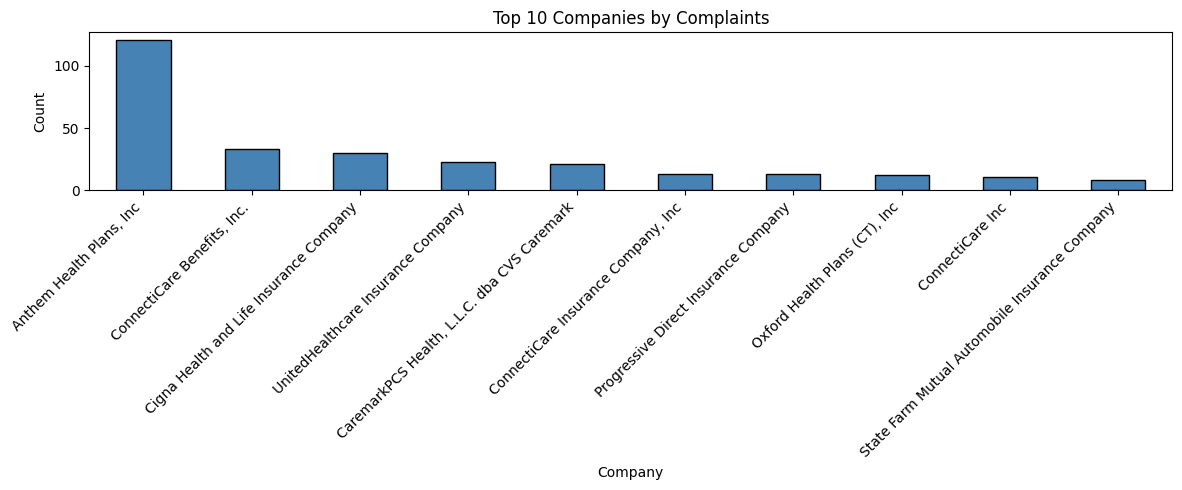

In [ ]:
#Bar Chart - Top 10 Companies by Complaints
plt.figure(figsize=(12,5))
df['Company'].value_counts().head(10).plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Top 10 Companies by Complaints')
plt.xlabel('Company'); plt.ylabel('Count')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

**Visualization 1 – Top 10 Insurance Companies by Complaint Count**

**Objective:**
To identify which insurance companies received the highest number of complaints.

**Visualization:** Bar Chart

**Interpretation:**

Anthem Health Plans, Inc dominates with 121 complaints — the highest among all 121 companies.
ConnectiCare Benefits, Inc. (33) and Cigna Health and Life Insurance Company (30) follow as 2nd and 3rd.
Top 3 companies together account for 184 out of 500 complaints (36.8% of total).
Remaining companies have significantly fewer complaints, showing a highly skewed distribution.

**Key Insight:**
Anthem Health Plans, Inc alone contributes 24.2% of all complaints, indicating concentrated service issues in a single company.

**Business Insight:**
Insurance regulators should prioritize auditing high-complaint companies like Anthem Health Plans to enforce stricter service quality standards and protect consumers.

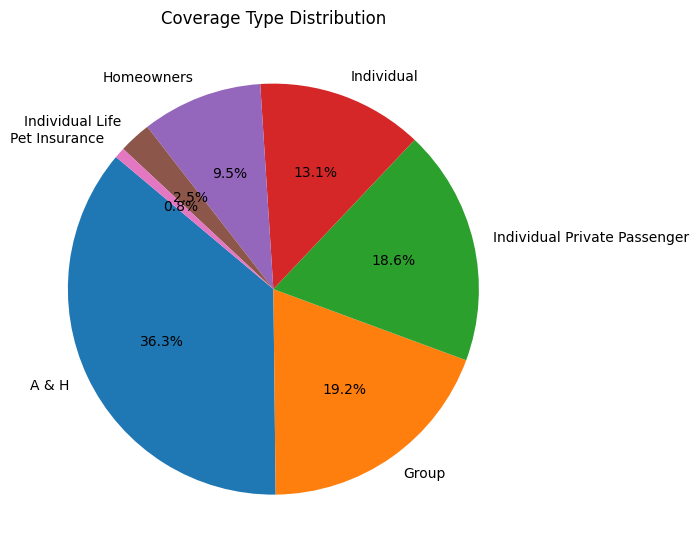

In [ ]:
#Pie Chart - Coverage Type Distribution
plt.figure(figsize=(7,7))
df['Coverage'].value_counts().head(7).plot(kind='pie', autopct='%1.1f%%', startangle=140)
plt.title('Coverage Type Distribution'); plt.ylabel(''); plt.tight_layout(); plt.show()

**Visualization 2 – Coverage Type Distribution**

**Objective:**
To understand which types of insurance coverage generate the most complaints.

**Visualization:** Pie Chart

**Interpretation:**

A & H (Accident & Health) coverage accounts for the largest share with 172 complaints (34.4%).
Group coverage (91 = 18.2%) and Individual Private Passenger (88 = 17.6%) follow closely.
Individual coverage (62 = 12.4%) and Homeowners (45 = 9%) are the next significant categories.
Remaining 16 coverage types together account for less than 9% of complaints.

**Key Insight:**
A & H (Accident & Health) is the most complaint-prone coverage type, representing over one-third of all complaints.

**Business Insight:**
Insurance companies should focus on improving A & H and Group coverage processes, as these two categories alone account for over 52% of all complaints.

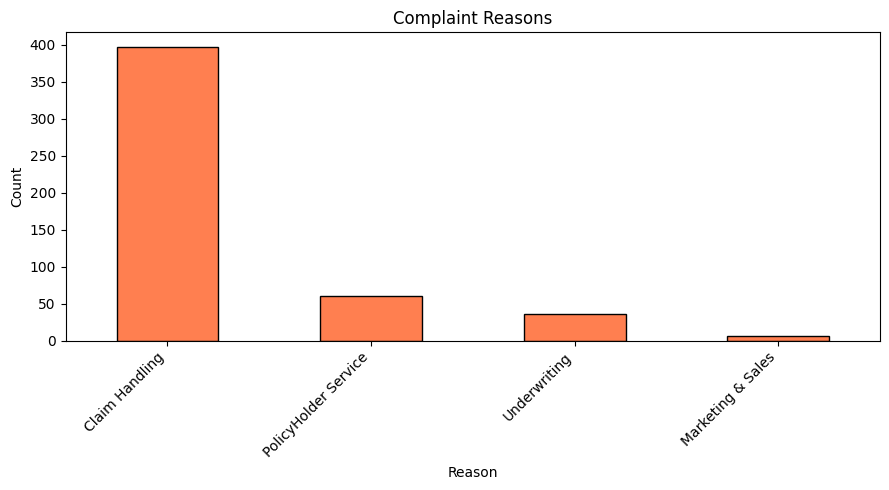

In [ ]:
#Bar Chart - Complaint Reasons
plt.figure(figsize=(9,5))
df['Reason'].value_counts().plot(kind='bar', color='coral', edgecolor='black')
plt.title('Complaint Reasons'); plt.xlabel('Reason'); plt.ylabel('Count')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

**Complaint Reasons Distribution**

**Objective:**
To identify the most frequent reasons customers file insurance complaints.

**Visualization**: Bar Chart

**Interpretation:**

Claim Handling is the dominant reason with 397 complaints (79.4% of total).
PolicyHolder Service accounts for 61 complaints (12.2%).
Underwriting follows with 36 complaints (7.2%).
Marketing & Sales has the lowest with only 6 complaints (1.2%).

**Key Insight:**
Claim Handling alone drives nearly 80% of all complaints, indicating a critical failure point in the insurance claims process.

**Business Insight:**
Insurance companies must urgently invest in claims department reform — including faster processing, transparent communication, and better adjuster training — to address the root cause of 4 out of 5 complaints

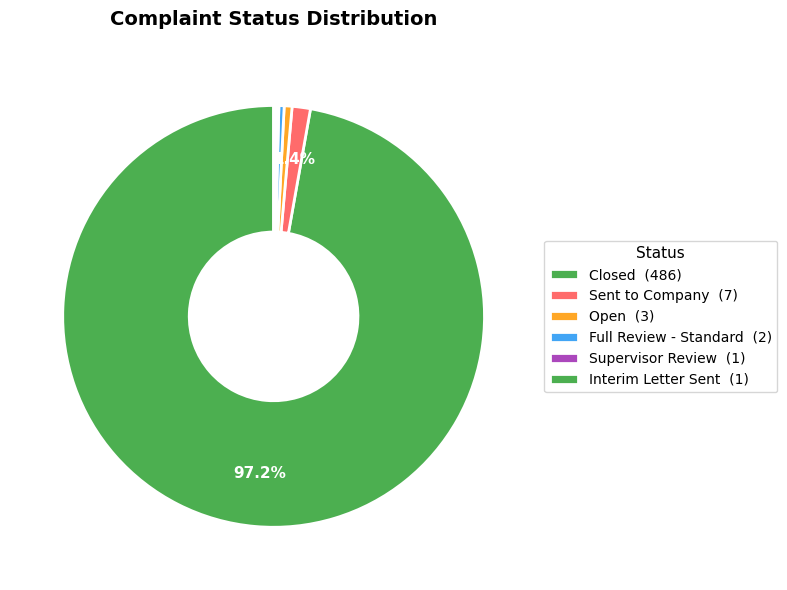

In [ ]:
#Pie Chart
status_counts = df['Status'].value_counts()
colors = ['#4CAF50', '#FF6B6B', '#FFA726', '#42A5F5', '#AB47BC']

fig, ax = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax.pie(
    status_counts,
    autopct=lambda p: f'{p:.1f}%' if p > 1 else '',
    colors=colors[:len(status_counts)],
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2)
)

for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')
    autotext.set_color('white')

ax.legend(wedges, [f'{label}  ({count:,})' for label, count in zip(status_counts.index, status_counts.values)],
    title='Status', title_fontsize=11, loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=10)

ax.set_title('Complaint Status Distribution', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout(); plt.show()

**Complaint Status Distribution**

**Objective:**
To analyze the proportion of resolved vs unresolved complaints.

**Visualization:** Pie Chart

**Interpretation**:

486 complaints (97.2%) are Closed — indicating high resolution rate.
7 complaints (1.4%) are Sent to Company — pending company response.
3 complaints (0.6%) remain Open — actively unresolved.
Full Review, Supervisor Review, and Interim Letter together account for less than 1%.

**Key Insight:**
97.2% complaint closure rate reflects strong resolution performance; however, 14 complaints (2.8%) remain in active/pending stages requiring follow-up.

**Business Insight:**
Maintaining near-complete closure rates while actively monitoring the small Open and Sent-to-Company cases will help sustain high customer satisfaction levels.

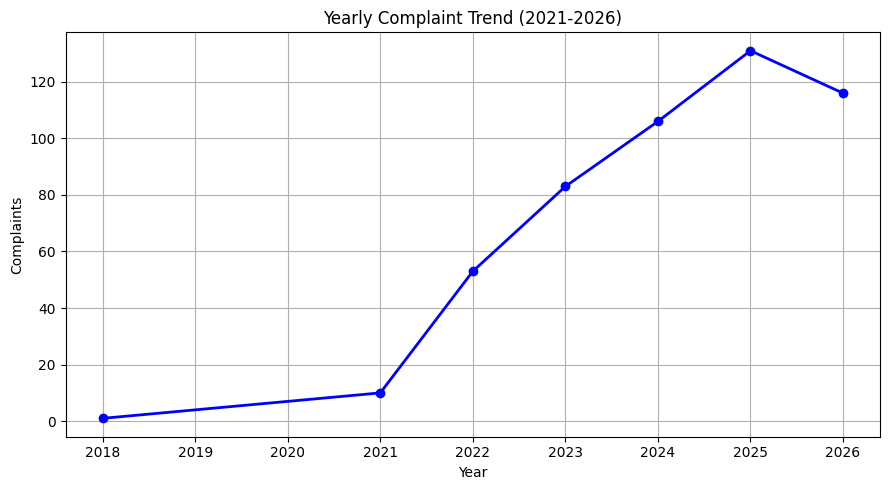

In [ ]:
#Line Chart - Yearly Complaint Trend
plt.figure(figsize=(9,5))
df['Year'].value_counts().sort_index().plot(kind='line', marker='o', color='blue', linewidth=2)
plt.title('Yearly Complaint Trend (2021-2026)'); plt.xlabel('Year'); plt.ylabel('Complaints')
plt.grid(True); plt.tight_layout(); plt.show()

**Yearly Complaint Trend (2021–2026)**

Objective:
To identify how insurance complaint volume has changed year over year from 2021 to 2026.

**Visualization**: Line Chart

**Interpretation:**

Complaints grew steadily from 10 in 2021 to a peak of 131 in 2025.
2024 (106) and 2025 (131) show the highest complaint volumes in the dataset.
2026 recorded 116 complaints — slightly lower than 2025 but still high (may represent partial year data).
2022 (53) and 2023 (83) show consistent year-on-year growth.

**Key Insight:**
Complaint volume increased by 1,210% from 2021 to 2025, suggesting worsening customer experience or growing customer awareness of complaint filing processes.

**Business Insight:**
The sharp upward trend from 2022 to 2025 signals the need for proactive complaint reduction strategies, including better customer communication and faster claim settlements.

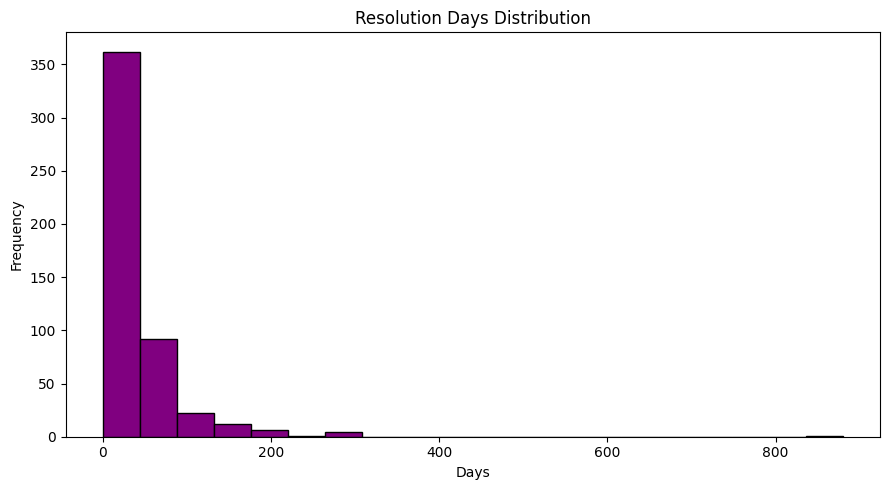

In [ ]:
#Histogram - Resolution Days Distribution
plt.figure(figsize=(9,5))
df['Resolution_Days'].dropna().plot(kind='hist', bins=20, color='purple', edgecolor='black')
plt.title('Resolution Days Distribution'); plt.xlabel('Days'); plt.ylabel('Frequency')
plt.tight_layout(); plt.show()

**Complaint Resolution Days Distribution**

**Objective:**
To understand the distribution of time taken to resolve insurance complaints.

**Visualization**: Histogram

**Interpretation:**
Average resolution time is 42.06 days; median is 28.5 days.
103 complaints (20.6%) resolved Fast (0–15 days).
160 complaints (32%) resolved in Medium time (16–30 days).
237 complaints (47.4%) took Slow resolution (above 30 days).
Maximum resolution time recorded is 880 days — a significant outlier.

**Key Insight:**
Nearly half of all complaints (47.4%) take more than 30 days to resolve, and one extreme case took 880 days, highlighting serious delays in some cases.

**Business Insight:**
Setting a 30-day resolution target and implementing escalation protocols for cases exceeding 60 days could significantly improve customer satisfaction and reduce regulatory risk.

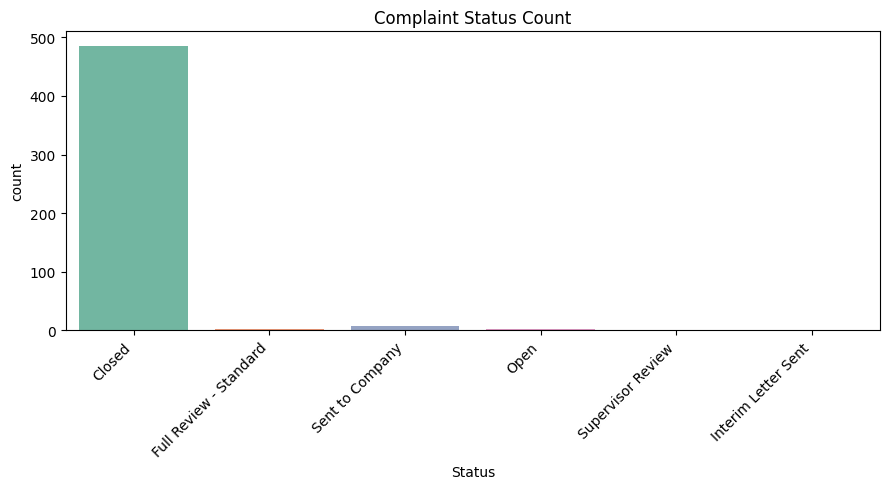

In [ ]:
#Count Plot - Complaint Status Count
plt.figure(figsize=(9,5))
sns.countplot(data=df, x='Status', palette='Set2')
plt.title('Complaint Status Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Complaint Status Count Plot**

**Objective:**
To clearly visualize the total count comparison between different complaint statuses.

**Visualization:** Count Plot (Seaborn)

**Interpretation:**

Closed status dominates with 486 complaints vs only 3 Open complaints.
Sent to Company (7) represents complaints still awaiting company response.
The visual contrast clearly shows the overwhelming majority of complaints are resolved.

**Key Insight:**
The massive gap between Closed (486) and Open (3) confirms that the complaint resolution system is highly effective overall.

**Business Insight:**
While closure rate is strong, the 7 complaints Sent to Company should be tracked with deadlines to prevent them from aging into unresolved cases.

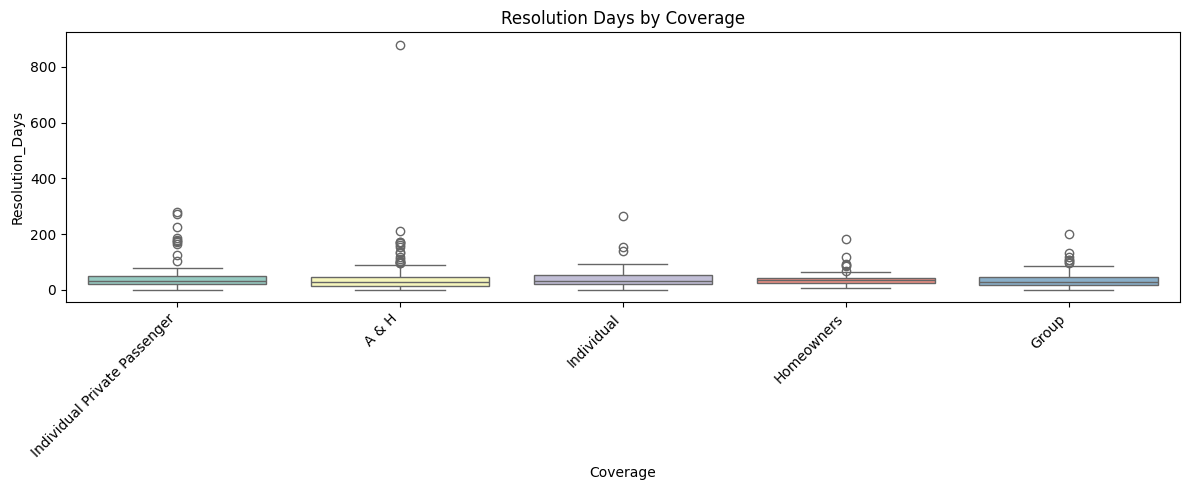

In [ ]:
#Box Plot - Resolution Days by Coverage Type
plt.figure(figsize=(12,5))
sns.boxplot(data=df[df['Coverage'].isin(df['Coverage'].value_counts().head(5).index)],
            x='Coverage', y='Resolution_Days', palette='Set3')
plt.title('Resolution Days by Coverage'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

**Resolution Days by Coverage Type (Box Plot)**

**Objective:**
To compare complaint resolution speed across the top 5 insurance coverage types.

**Visualization:** Box Plot (Seaborn)

**Interpretation:**

Individual Private Passenger has the highest average resolution time at 49.43 days.
A & H follows at 42.83 days, and Homeowners at 41.49 days.
Group coverage is the fastest to resolve at 36.01 days average.
All coverage types show outliers, indicating some cases take significantly longer than average.

**Key Insight:**
Individual Private Passenger coverage takes the longest to resolve on average (49.43 days), nearly 38% longer than Group coverage (36.01 days).

**Business Insight:**
Dedicated resolution teams for Individual Private Passenger and A & H complaints could reduce resolution time and improve customer retention in these high-complaint coverage segments.

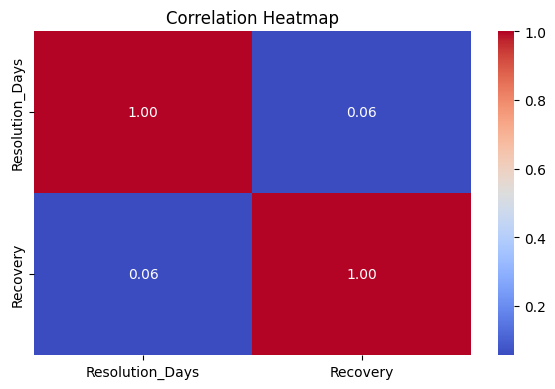

In [ ]:
#Heatmap - Correlation Matrix
plt.figure(figsize=(6,4))
sns.heatmap(df[['Resolution_Days','Recovery']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap'); plt.tight_layout(); plt.show()

**Correlation Heatmap**

**Objective:**
To identify the statistical relationship between Resolution_Days and Recovery amount.

**Visualization:** Heatmap (Seaborn)

**Interpretation:**

Correlation between Resolution_Days and Recovery is very low (near 0).
This means longer resolution times do not lead to higher recovery amounts.
The two variables operate independently of each other.

**Key Insight:**
Resolution time and financial recovery are independent metrics — resolving a complaint faster does not reduce or increase the recovery amount paid.

**Business Insight:**
Companies should focus on reducing resolution time as a separate KPI from financial recovery, as speed of resolution primarily impacts customer satisfaction rather than financial outcomes.

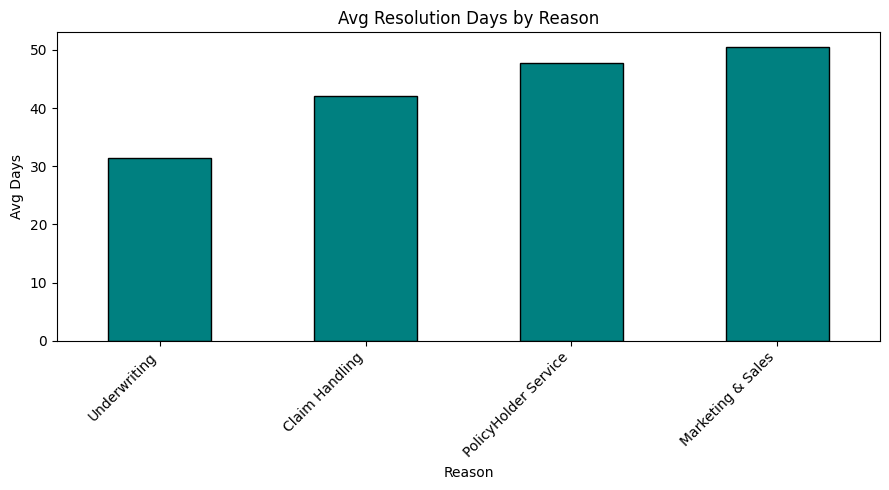

In [ ]:
#Bar Chart - Avg Resolution Days by Reason
plt.figure(figsize=(9,5))
df.groupby('Reason')['Resolution_Days'].mean().sort_values().plot(kind='bar', color='teal', edgecolor='black')
plt.title('Avg Resolution Days by Reason'); plt.xlabel('Reason'); plt.ylabel('Avg Days')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

**Average Resolution Days by Complaint Reason**

**Objective:**
To identify which complaint reasons take the longest time to resolve on average.

**Visualization:** Bar Chart

**Interpretation:**

Marketing & Sales complaints take the longest to resolve at 50.50 days average.
PolicyHolder Service follows at 47.75 days average.
Claim Handling averages 42.02 days — despite being the most frequent complaint type.
Underwriting is resolved fastest at 31.39 days average.

**Key Insight:**
Despite being the most common complaint, Claim Handling is not the slowest to resolve. Marketing & Sales and PolicyHolder Service complaints take longer on average despite lower volumes.

**Business Insight:**
Targeted process improvement for PolicyHolder Service and Marketing & Sales teams can reduce resolution times for these categories, as their complexity causes delays disproportionate to their complaint volume.

In [ ]:
#Key Insights
print("="*50)
print("KEY INSIGHTS")
print("="*50)
print("Total Complaints        :", len(df))
print("Status:\n",                  df['Status'].value_counts())
print("Top 3 Companies:\n",         df['Company'].value_counts().head(3))
print("Most Common Reason      :",  df['Reason'].value_counts().idxmax())
print("Most Common Coverage    :",  df['Coverage'].value_counts().idxmax())
print("Avg Resolution Days     :",  round(df['Resolution_Days'].mean(),2))
print("Total Recovery Amount $ :",  round(df['Recovery'].sum(),2))
print("Year with Most Complaints:", df['Year'].value_counts().idxmax())


KEY INSIGHTS
Total Complaints        : 500
Status:
 Status
Closed                    486
Sent to Company             7
Open                        3
Full Review - Standard      2
Supervisor Review           1
Interim Letter Sent         1
Name: count, dtype: int64
Top 3 Companies:
 Company
Anthem Health Plans, Inc                   121
ConnectiCare Benefits, Inc.                 33
Cigna Health and Life Insurance Company     30
Name: count, dtype: int64
Most Common Reason      : Claim Handling
Most Common Coverage    : A & H
Avg Resolution Days     : 42.06
Total Recovery Amount $ : 878358.86
Year with Most Complaints: 2025


## Conclusion
- Majority of complaints are **Closed** successfully
- **Claim Handling** is the most common complaint reason
- Average complaint resolution takes around **30–40 days**
- A few insurance companies account for most complaints
- Recovery amounts vary significantly by coverage type
- Complaint volume shows yearly variation from 2021 to 2026
- This analysis helps identify areas for improvement in insurance complaint handling